# Historia 2 — Czas przed ekranem

Zbadano **40 nastolatków**. Średnio spędzają przed ekranem **4,5 godziny dziennie**, a odchylenie standardowe z próby wynosi **1,2 godziny**.

**Cel:** oszacować średni czas przed ekranem dla wszystkich nastolatków przy **95% poziomie ufności**.

Zamiast badać wszystkich, korzystamy z wyników małej grupy.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Krok 1. Zapisujemy dane
Wpisujemy średni czas, odchylenie standardowe i liczbę nastolatków.

In [3]:
srednia2 = 4.5
odchylenie2 = 1.2
n2 = 40
ufnosc2 = 0.95
stopnie_swobody2 = n2 - 1

print(f"Średnia: {srednia2} h; odchylenie: {odchylenie2} h; n = {n2}")

Średnia: 4.5 h; odchylenie: 1.2 h; n = 40


### Krok 2. Obliczamy przedział ufności
Program oblicza, jak dokładne jest nasze oszacowanie średniej. Korzystamy z rozkładu t, ponieważ znamy odchylenie standardowe próby, a nie całej populacji.

In [4]:
t2 = stats.t.ppf((1 + ufnosc2) / 2, df=stopnie_swobody2)
se2 = odchylenie2 / np.sqrt(n2)
margines2 = t2 * se2
ci2_dol = srednia2 - margines2
ci2_gora = srednia2 + margines2

ci2_kontrola = stats.t.interval(ufnosc2, df=stopnie_swobody2,
                               loc=srednia2, scale=se2)
assert np.allclose([ci2_dol, ci2_gora], ci2_kontrola)

print(f"Wartość krytyczna t: {t2:.4f}")
print(f"Błąd standardowy: {se2:.4f} h")
print(f"Margines błędu: ±{margines2:.4f} h")
print(f"95% przedział ufności: ({ci2_dol:.3f}; {ci2_gora:.3f}) h")

Wartość krytyczna t: 2.0227
Błąd standardowy: 0.1897 h
Margines błędu: ±0.3838 h
95% przedział ufności: (4.116; 4.884) h


### Krok 3. Tworzymy wykres
Na środku widzimy średnią z próby. Zaznaczamy też dolną i górną granicę przedziału ufności.

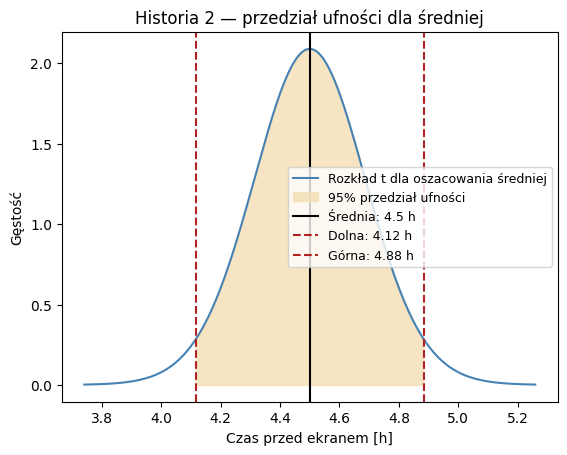

In [5]:
x_wykres2 = np.linspace(srednia2 - 4 * se2, srednia2 + 4 * se2, 500)
y_wykres2 = stats.t.pdf((x_wykres2 - srednia2) / se2, df=stopnie_swobody2) / se2

fig, ax = plt.subplots()
ax.plot(x_wykres2, y_wykres2, color="steelblue", label="Rozkład t dla oszacowania średniej")
ax.fill_between(x_wykres2, y_wykres2,
                where=(x_wykres2 >= ci2_dol) & (x_wykres2 <= ci2_gora),
                color="wheat", alpha=0.8, label="95% przedział ufności")
ax.axvline(srednia2, color="black", label=f"Średnia: {srednia2:.1f} h")
ax.axvline(ci2_dol, color="firebrick", linestyle="--", label=f"Dolna: {ci2_dol:.2f} h")
ax.axvline(ci2_gora, color="firebrick", linestyle="--", label=f"Górna: {ci2_gora:.2f} h")
ax.set(title="Historia 2 — przedział ufności dla średniej", xlabel="Czas przed ekranem [h]", ylabel="Gęstość")
ax.legend(fontsize=9)
plt.show()

### Wniosek
Szacujemy, że nastolatki spędzają średnio przed ekranem **od 4,12 do 4,88 godziny dziennie**. Jest to **95% przedział ufności dla średniej**, a nie zakres czasu dla pojedynczych osób.